# Reading Guide: How This Research Was Built, Step by Step

**Paper:** *Quantifying the Predictive Contribution of Hard X-ray, Soft X-ray, and EUV Observations for Early Solar Flare Forecasting: Evidence from Aditya-L1*

This notebook is a **textbook of the whole project**. It explains what was done, why, what went wrong, and what each result does and does not show. It is meant to be *read* from top to bottom. Every table and figure below is **loaded live from the result files in this folder**, so the numbers here are the same as the paper's.

How the chapters are marked:

* > **GOOD DECISION.** a choice that made the research better, and why.
* > **BAD DECISION / MISTAKE.** a choice that cost time or weakened the work, and what we did about it.
* > **NOTE.** something you should remember when you explain the work to someone else.

**Be able to answer these three questions at the end:** What exactly was predicted? How do we know the model is not cheating? What does each result actually show, and what does it *not* show?

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib
matplotlib.rcParams.update({"figure.dpi": 110, "font.size": 9})
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path("..").resolve()
OUT = ROOT / "outputs_adl1"; TB = OUT / "tables"; FG = OUT / "figures"; PROC = ROOT / "data" / "processed_adl1"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
def show_png(p, width=700):
    p = Path(p)
    display(Image(filename=str(p), width=width)) if p.exists() else print("missing:", p.name)
def load(name, folder=TB):
    p = Path(folder) / name
    return pd.read_csv(p) if p.exists() else None
print("project root:", ROOT)

project root: C:\Users\jayag\OneDrive\Desktop\solar-flare-xray


# Chapter 1. The question

## 1.1 Where it started
The project began as problem statement 15 of the Bharatiya Antariksh Hackathon 2026: *build a pipeline using Aditya-L1 soft and hard X-ray data to nowcast and forecast solar flares.* The team proposal (TRiYana) planned a large system: multi-source fusion, SDO/HMI magnetic parameters (SHARP), a CNN-BiLSTM, graded alerts, impact assessment.

## 1.2 What we actually studied
A hackathon rewards a working demo. A research paper needs a **question with an answer**. We turned the project into:

> *How much does each observing band (hard X-ray, soft X-ray, EUV) add to a short-notice flare forecast, alone and in combination, **beyond what recent flare activity already tells you**?*

> **GOOD DECISION.** Asking *contribution of each band* instead of *which classifier scores highest* gives the paper a scientific argument. A model score tells you about the model; a contribution tells you about the Sun.

> **BAD DECISION / MISTAKE.** The proposal promised magnetic-field (SHARP) features. We never had them, so the study can say nothing about forecasting that uses magnetic data, which is where most published skill comes from. The paper states this as a limitation, but it is a real gap, not a footnote.

## 1.3 The three bands in one paragraph each
* **Soft X-ray (SXR)**: from hot (millions of kelvin) plasma. Rises *with* the flare and decays slowly. GOES flare classes (B, C, M, X) are defined from it. We use **SoLEXS** on Aditya-L1.
* **Hard X-ray (HXR)**: from fast electrons slamming into the lower atmosphere. A short, sharp burst during the *impulsive* phase. We use **HEL1OS** (CZT detectors, 20 to 150 keV).
* **EUV**: emission lines from the transition region and chromosphere. We use **GOES-16 EUVS** lines at 25.6, 28.4 and 30.4 nm at 1-minute cadence.

**The Neupert effect:** the HXR light curve looks like the *time derivative* of the SXR light curve. Physically: electrons (HXR) heat plasma that evaporates upward and fills the loop (SXR). So HXR tells you *when energy is being injected*, SXR tells you *how much has accumulated*.

# Chapter 2. What a flare looks like in the data

Before any modelling, **look at the data**. The strongest flare in the window was an X8.9 on 3 October 2024. Below we plot one hour either side from our own processed files.

strongest flare (class | date | peak time UTC): X8.9|03 October 2024|12:18


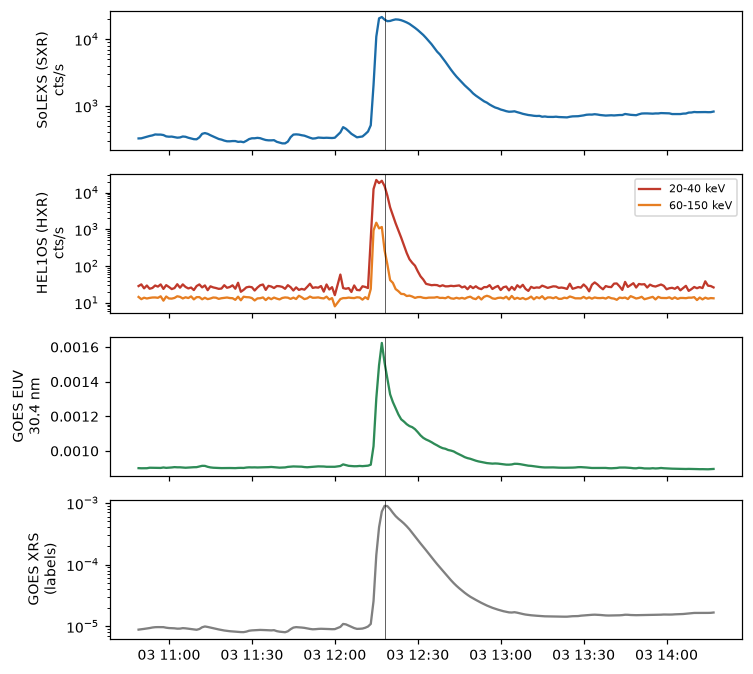

In [2]:
ex = (TB / "example_flare.txt").read_text().strip() if (TB / "example_flare.txt").exists() else ""
print("strongest flare (class | date | peak time UTC):", ex)
sx = pd.read_csv(PROC/"solexs_1min.csv", parse_dates=["time"]); hx = pd.read_csv(PROC/"hel1os_1min.csv", parse_dates=["time"]); gs = pd.read_csv(PROC/"goes_1min.csv", parse_dates=["time"])
d = sx.merge(hx, on="time").merge(gs[["time","irr_304","xrsb_flux"]], on="time", how="left").sort_values("time")
t0 = pd.Timestamp("2024-10-03 12:18", tz="UTC"); w = d[(d.time > t0 - pd.Timedelta("90min")) & (d.time < t0 + pd.Timedelta("120min"))]
fig, ax = plt.subplots(4, 1, figsize=(7, 6.2), sharex=True)
ax[0].semilogy(w.time, w.sxr_cps, color="#1b6ca8"); ax[0].set_ylabel("SoLEXS (SXR)\ncts/s")
ax[1].semilogy(w.time, w.czt_20_40, color="#c0392b", label="20-40 keV"); ax[1].semilogy(w.time, w.czt_60_80 + w.czt_80_150, color="#e67e22", label="60-150 keV"); ax[1].set_ylabel("HEL1OS (HXR)\ncts/s"); ax[1].legend(fontsize=7)
ax[2].plot(w.time, w.irr_304, color="#2e8b57"); ax[2].set_ylabel("GOES EUV\n30.4 nm")
ax[3].semilogy(w.time, w.xrsb_flux, color="gray"); ax[3].set_ylabel("GOES XRS\n(labels)")
for a in ax: a.axvline(t0, color="k", lw=.4)
plt.tight_layout(); plt.show()

**What to notice.** The HXR burst (red/orange) is a tall, narrow spike that is *over before the SXR peaks*. The SXR curve rises while HXR is on, then decays slowly. EUV barely moves at this scale. That is the Neupert effect in one picture.

> **NOTE.** Nothing in the hour *before* the flare shows an obvious precursor in any band. That is the central difficulty: forecasting has to find weak, indirect hints, while nowcasting has a huge signal to latch onto. Keep this contrast in mind for the whole project.

# Chapter 3. Getting the data (and everything that went wrong)

## 3.1 Where each piece came from
| Need | Source | Access |
|---|---|---|
| Soft X-ray | Aditya-L1 SoLEXS Level-1 (ISSDC PRADAN) | free account, login required |
| Hard X-ray | Aditya-L1 HEL1OS Level-1 (PRADAN) | free account, login required |
| EUV + flare labels | GOES-16 EUVS and XRS (NOAA NCEI) | public |
| SEP contamination flags | HEL1OS SEP catalog (PDF from PRADAN) | free account |

## 3.2 What a "daily file" really is
Each PRADAN file is a **zip inside a zip structure**. Only a small part is a light curve we need. Let us look inside one.

In [3]:
import zipfile, glob
sol = glob.glob(r"C:\solar-data\aditya\solexs\**\AL1_SLX_L1_20241212_v*.zip", recursive=True)
hel = glob.glob(r"C:\solar-data\aditya\hel1os\**\HLS_20241212_000*_V*.zip", recursive=True)
for f in (sol[:1] + hel[:1]):
    z = zipfile.ZipFile(f); info = z.infolist()
    print(Path(f).name, "->", len(info), "entries; compressed MB:", round(sum(i.compress_size for i in info)/1e6, 1))
    big = sorted(info, key=lambda i: -i.compress_size)[:4]
    for i in big: print("   ", round(i.compress_size/1e6, 2), "MB ", i.filename.split("/", 2)[-1][:70])

AL1_SLX_L1_20241212_v1.0.zip -> 7 entries; compressed MB: 6.2
    5.92 MB  AL1_SOLEXS_20241212_SDD2_L1.pi.gz
    0.24 MB  AL1_SOLEXS_20241212_SDD2_L1.lc.gz
    0.0 MB  AL1_SOLEXS_20241212_SDD2_L1.gti.gz
    0.0 MB  AL1_SOLEXS_20241212_SDD1_L1.gti.gz
HLS_20241212_000012_43172sec_lev1_V111.zip -> 22 entries; compressed MB: 41.5
    31.32 MB  12/HLS_20241212_000012_43172sec_lev1_V111/events/evt.fits
    1.96 MB  12/HLS_20241212_000012_43172sec_lev1_V111/czt/lightcurve_czt2.fits
    1.96 MB  12/HLS_20241212_000012_43172sec_lev1_V111/czt/lightcurve_czt1.fits
    1.78 MB  12/HLS_20241212_000012_43172sec_lev1_V111/cdte/lightcurve_cdte2.fits


For SoLEXS, the file we need (`.lc.gz`, the light curve) is about **0.25 MB**, while the spectra (`.pi.gz`) are about **6 MB**. We can only download whole days, so about 96% of every download is data we never use.

## 3.3 The download story (a decision log in prose)

1. **Plan A: Fermi/GBM as the hard X-ray source.** PRADAN needs a login, which an automated assistant must not create or use, so we started with public Fermi data.
   > **GOOD DECISION.** Using a public proxy let the analysis start immediately and gave us a pipeline to test. It later became the preliminary study.
2. **NOAA's server turned out slow** (about 15 to 33 s per tiny file) and parallel downloads did not help. We repeatedly *shrank the scope* (a full year, then 3 months, then 3 weeks).
   > **BAD DECISION / MISTAKE.** We committed to big downloads before measuring the real transfer speed. Measure first, plan second.
3. **Corrupt files were silently accepted.** The batch downloader only checked "file size > 0", so truncated transfers were kept. Twenty-one EUV files failed to open later.
   > **BAD DECISION / MISTAKE.** A size check is not an integrity check. We added a step that *opens every file* and re-downloads failures.
4. **The website's "zip and download" option kept cutting off** (about 18 MB of 141 MB) and produced an invalid zip. PRADAN's **bulk script option** worked: it resumes, retries, and ran about 10x faster.
   > **GOOD DECISION.** We read the generated script before running it: it only contacts PRADAN, uses no shell or deletion calls, and relies on the user's own session cookie.
5. **Scope decisions by size:** SoLEXS is about 7 to 10 MB/day (small), but HEL1OS is about 100 MB/day. We asked before downloading 10 GB, then did the full 204 files. A watcher script stopped HEL1OS at 100 files, and later the rest was fetched.
6. **Everything outside OneDrive.** The 11 GB of raw data lives in `C:\solar-data\` so the project folder does not sync gigabytes to the cloud.

> **NOTE.** Never judge a data pipeline by whether the download "finished". Judge it by whether every file opens and checksums.

# Chapter 4. From raw light curves to a clean 1-minute table

## 4.1 The rules
* SoLEXS: detector SDD2, 1-second counts per second. HEL1OS: CZT1 + CZT2 summed, bands 20 to 40, 40 to 60 and 60 to 150 keV (the last is 60 to 80 plus 80 to 150).
* **Average to 1 minute, but only if at least 30 valid seconds exist** in that minute. Otherwise the minute is missing, not zero.
* When two processing versions of a file exist (v1.0 vs v1.1; V111 vs V211), keep the **newest**.

> **GOOD DECISION.** Missing means *missing*. Filling gaps with zeros or interpolating would invent data, and it would invent it exactly where instruments had problems.

> **NOTE.** Why 1 minute? GOES EUV is only available at 1-minute cadence, and the labels are minute-resolved. The cost: sub-minute HXR bursts that might be genuine precursors are averaged away. This is a *known limit*, and it appears in the paper's discussion.

## 4.2 How complete is the data?

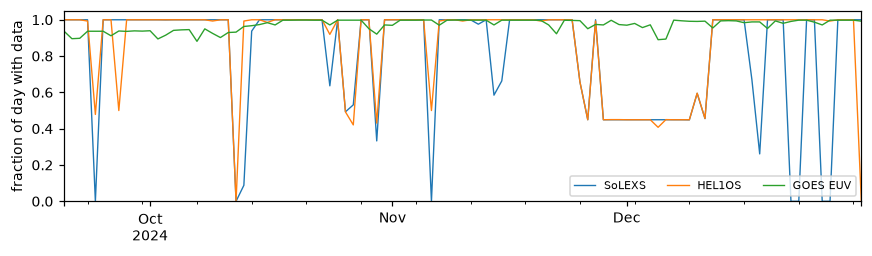

days with <50% coverage -> SoLEXS: 25 | HEL1OS: 20 | GOES EUV: 0  (of 103 days)


In [4]:
g = pd.read_csv(PROC/"goes_1min.csv", parse_dates=["time"])
days = pd.date_range("2024-09-20", "2024-12-31", freq="D", tz="UTC")
def frac(s):   # valid minutes per day / 1440 ; days with no rows at all count as 0
    return (s.dropna().resample("D").count() / 1440).reindex(days, fill_value=0)
cov = pd.DataFrame({"SoLEXS": frac(sx.set_index("time").sxr_cps), "HEL1OS": frac(hx.set_index("time").czt_20_40), "GOES EUV": frac(g.set_index("time").irr_304)})
fig, ax = plt.subplots(figsize=(8, 2.4)); cov.plot(ax=ax, lw=.9); ax.set_ylabel("fraction of day with data"); ax.set_ylim(0, 1.05); ax.legend(ncol=3, fontsize=7); plt.tight_layout(); plt.show()
print("days with <50% coverage -> SoLEXS:", int((cov.SoLEXS < .5).sum()), "| HEL1OS:", int((cov.HEL1OS < .5).sum()), "| GOES EUV:", int((cov["GOES EUV"] < .5).sum()), " (of", len(days), "days)")

Gaps are real: the plot shows days where SoLEXS has no data, HEL1OS days where only one 12-hour segment exists (about half a day), and GOES days with flagged data. (In the earlier May study GOES even had a day with 94% of soft X-ray minutes flagged.) All of these simply become *missing rows*; a minute is used in the analysis only if every band has data.

## 4.3 The bug-prone step: reading time
Times came in four different formats (unix seconds, MJD, ISO text, seconds since 2000-01-01 12:00). Every one was converted to **UTC minute stamps by flooring**. Mixing these up silently misaligns bands, so alignment was verified by checking that the merged table had the expected number of rows and that the Neupert correlation was positive (a physics sanity check that would fail if the clocks were off by even a few minutes).

# Chapter 5. What exactly are we predicting?

## 5.1 The label
For every minute *t*:

> `y_H(t) = 1` if a **new** flare of class C or above **starts** within the next *H* minutes (H = 15, 30, 60). The same for M-class and above with H = 30, 60.

Two design choices hide inside that sentence.

**(a) "Starts", not "occurs".** If we asked "is there a flare in the next hour", then minutes *during* a flare would trivially say yes (the flare is already happening and visible in SXR). Predicting *starts* forces the model to find warning signs.

**(b) Rows inside an ongoing flare are removed.** Otherwise the model could simply notice "a flare is already underway" and look clever.

> **GOOD DECISION.** Both choices make the task honest.

> **BAD DECISION / MISTAKE.** Choice (b) uses the flare's **end time**, which a live system would not know at that moment. A real system would only know a flare is ongoing after it detected it, a few minutes in. This is a small hindsight advantage, so it is stated as a limitation in the paper. A reviewer rightly pointed it out; we did not see it until then.

In [5]:
f = pd.read_csv(PROC/"features_adl1.csv", usecols=["time","y15","y30","y60","yM30","yM60","complete","sep","ongoing"], parse_dates=["time"])
u = f[(f.complete) & (~f.sep)]
t = pd.DataFrame({"positive minutes": [int(u[c].sum()) for c in ["y15","y30","y60","yM30","yM60"]], "base rate": [u[c].mean() for c in ["y15","y30","y60","yM30","yM60"]]}, index=["C+ in 15 min","C+ in 30 min","C+ in 60 min","M+ in 30 min","M+ in 60 min"])
print("usable minutes:", len(u), "of", len(f), "| inside ongoing flares:", int(f.ongoing.sum()), "| SEP flagged:", int(f.sep.sum())); t

usable minutes: 87245 of 146880 | inside ongoing flares: 15797 | SEP flagged: 17985


,positive minutes,base rate
C+ in 15 min,8476,0.097
C+ in 30 min,16156,0.185
C+ in 60 min,29065,0.333
M+ in 30 min,4397,0.050
M+ in 60 min,8267,0.095


> **NOTE.** The **base rate** matters. If 33% of minutes are positive (C+ in 60 min), a lazy model that always says "yes" already catches every flare. That is why we use TSS (Chapter 7) instead of accuracy.

## 5.2 The features
Every feature at minute *t* is computed from data **at or before** *t*. For each channel:

| Feature | Meaning |
|---|---|
| log level (HXR: excess over a 3-hour running median) | how bright now (above the background for HXR) |
| change over 5, 15, 30 min | recent trend |
| curvature | is the rise accelerating |
| rolling SD (15, 60 min) | how jumpy |
| distance below the 60-min maximum | has it recently been higher |
| HXR hardness (60-150 / 20-40 keV) | spectral shape |
| **Neupert block**: HXR excess minus SXR derivative (standardised), rolling correlation | does HXR track dSXR/dt |
| **Flare history** (always included): flares started in last 6 h / 24 h, hours since last flare, strongest peak in 24 h, M+ count in 24 h | what recent activity already tells you |

> **GOOD DECISION.** **The flare-history block is in every model.** The question is what each band adds *beyond* it. Without this, a band could look useful just because it correlates with "an active region is flaring a lot", which history already tells you for free.

## 5.3 Proving the features do not peek at the future
Claiming "features use only past data" is easy; **proving** it is better. The test: recompute the features after *deleting all data after a cut time T*. If any feature at times up to T changes, it depended on the future.

In [6]:
c = load("causality_test.csv")
print(c.to_string(index=False) if c is not None else "causality test result not available yet")

           cut_time  rows_compared  n_features  max_abs_diff_all  n_features_with_differences  offending
2024-10-20 12:00:00          43921          67                 0                            0        NaN
2024-11-25 06:30:00          95431          67                 0                            0        NaN
2024-12-15 18:45:00         124966          67                 0                            0        NaN


> **BAD DECISION / MISTAKE.** **The first version of this test passed while comparing zero rows.** A time-format mismatch made the comparison table empty, and "no differences in an empty table" printed PASSED. We caught it only because the output said `rows_compared = 0`. The fix: the test now *fails* if fewer than 1,000 rows are compared. Lesson: **a test that cannot fail proves nothing**, so check that a passing test actually tested something.

# Chapter 6. How do we know the model is not cheating? Validation design

## 6.1 Why random train/test splits are wrong here
Consecutive minutes are almost copies of each other (a flare lasts tens of minutes). If a random minute is in the test set, its neighbours are in the training set, and the model "remembers" them. That produces scores that look great and are false.

## 6.2 What we did: blocked cross-validation
The 87,245 usable minutes are cut into **8 contiguous time blocks**. For each test block:
* the **next** block is the validation block, used *only* to choose the alert threshold (the probability above which we raise an alert, chosen to maximise TSS);
* all remaining blocks train the model;
* a **60-minute purge gap** is removed around test and validation blocks so labels and rolling windows cannot straddle a boundary;
* every 4th training minute is used (neighbouring minutes are redundant, and it is 4x faster).

All 8 test blocks are then pooled for scoring.

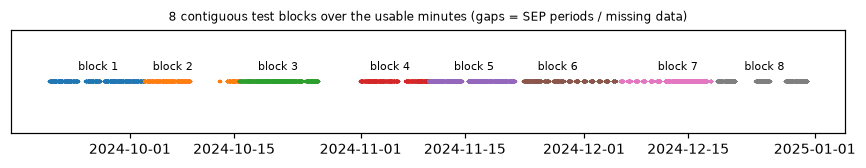

In [7]:
f2 = pd.read_csv(PROC/"features_adl1.csv", usecols=["time","complete","sep"], parse_dates=["time"]); u2 = f2[(f2.complete) & (~f2.sep)].reset_index(drop=True)
t0_, t1_ = u2.time.min(), u2.time.max(); span = (t1_ - t0_).total_seconds()
u2["fold"] = np.minimum(8, np.floor((u2.time - t0_).dt.total_seconds() / span * 8) + 1).astype(int)
fig, ax = plt.subplots(figsize=(8, 1.6)); cols = plt.cm.tab10(np.arange(8))
for k in range(1, 9):
    s = u2[u2.fold == k]; ax.scatter(s.time, np.zeros(len(s)), s=1, color=cols[k-1])
    ax.text(s.time.iloc[len(s)//2], .012, f"block {k}", ha="center", fontsize=7)
ax.set_yticks([]); ax.set_title("8 contiguous test blocks over the usable minutes (gaps = SEP periods / missing data)", fontsize=8); plt.tight_layout(); plt.show()

> **GOOD DECISION.** Blocking by time, with a purge gap and thresholds chosen on separate validation data, is the right basic design for autocorrelated time series.

## 6.3 The flaw we found late: "leave-one-block-out" is not "predict the future"
In this design a model testing on block 3 was trained on blocks 5 to 8 too, which is *later* in time. A real forecaster only has the past. The leakage is mild (blocks are separated by purge gaps, and the Sun does not "know" the future), but it can inflate scores because the model sees later activity regimes.

> **BAD DECISION / MISTAKE.** We described the validation as blocked but did not state this direction caveat in the first draft. A reviewer's "train on earlier observations and test on a later period" suggestion pointed straight at it.

**Fix:** we added a **forward-chaining** evaluation. Test block *k* is predicted using only blocks **before** *k-1* for training and block *k-1* for the threshold. Blocks 1 to 2 can only train, so forward results cover blocks 3 to 8. We compare both designs on the **same** test blocks below.

In [8]:
fw = load("forward_vs_loo_pooled.csv")
if fw is not None:
    s = fw.groupby("subset")[["TSS_loo","TSS_forward","diff"]].mean().round(3); display(s)
    print("mean change (forward minus leave-one-out) over all configurations:", round(fw["diff"].mean(), 3))
else: print("forward-chaining results not available yet")

,TSS_loo,TSS_forward,diff
subset,,,
EUV,0.187,0.141,-0.046
HXR,0.181,0.126,-0.055
HXR+EUV,0.193,0.147,-0.046
NONE,0.197,0.124,-0.072
SXR,0.216,0.133,-0.083
SXR+EUV,0.206,0.123,-0.083
SXR+HXR,0.221,0.124,-0.097
SXR+HXR+EUV,0.216,0.122,-0.093
level_only,0.114,0.016,-0.098


mean change (forward minus leave-one-out) over all configurations: -0.074


# Chapter 7. Models and the score we use

## 7.1 Three model families
Elastic-net **logistic regression** (simple and linear), **random forest** (many decision trees voting), **XGBoost** (trees built one after another to fix earlier errors). If a band's contribution only shows up in one family, it may be a quirk of that algorithm, not physics. We report the **consensus across the three**.

## 7.2 The score: True Skill Statistic
`TSS = POD - POFD`, where `POD` is the fraction of positive minutes we caught and `POFD` is the fraction of negative minutes we falsely flagged.
* `TSS = 0`: no skill (always-yes and always-no both score 0). `TSS = 1`: perfect.
* Unlike accuracy, it does **not** reward the "always no" strategy on rare events.

In [9]:
# A worked example with made-up counts: why accuracy lies on imbalanced data
tp, fn, fp, tn = 40, 60, 100, 800     # 100 positive minutes, 900 negative minutes
acc = (tp+tn)/(tp+fn+fp+tn); pod = tp/(tp+fn); pofd = fp/(fp+tn)
print(f"accuracy = {acc:.2f}  (looks fine!)   POD = {pod:.2f}   POFD = {pofd:.2f}   TSS = {pod-pofd:.2f}")
print("always-no model: accuracy =", (0+900)/1000, " TSS =", 0.0)

accuracy = 0.84  (looks fine!)   POD = 0.40   POFD = 0.11   TSS = 0.29
always-no model: accuracy = 0.9  TSS = 0.0


## 7.3 A bug that cost two hours: integer overflow
The first full model run took about an hour, **then returned almost nothing**. The cause was a single line in the score function. With about 80,000 test minutes, the product `(tp+fn)*(tp+fp)` exceeds the largest 32-bit integer.

In [10]:
a, b = np.int32(20000), np.int32(70000)
with np.errstate(over="ignore"):
    print("32-bit integer:", a*b, "(wrapped around - wrong, can even be negative)")
print("64-bit / float :", float(a)*float(b), "(correct)")

32-bit integer: 1400000000 (wrapped around - wrong, can even be negative)
64-bit / float : 1400000000.0 (correct)


Worse, the worker code **swallowed the error** (`tryCatch(..., error = function(e) NULL)`), so 124 of 125 experiments quietly returned nothing after running for an hour.

> **BAD DECISION / MISTAKE.** Two mistakes: (1) never tested the score function at realistic size, (2) hid errors behind a silent fallback. In the rerun the counts are stored as floating point **and** failures are collected and printed. Test small, but *also* test at full size on one example before launching an hour-long job. We did exactly that (a 90,000-row synthetic check) before the rerun.

# Chapter 8. The forecasting results, read honestly

In [11]:
R = load("results.csv"); order = ["NONE","SXR","HXR","EUV","SXR+HXR","SXR+EUV","HXR+EUV","SXR+HXR+EUV","level_only"]
tg = ["y15","y30","y60","yM30","yM60"]
t = R.pivot_table(index="subset", columns="target", values="TSS", aggfunc="mean").reindex(order)[tg].round(3)
t.columns = ["C+ 15","C+ 30","C+ 60","M+ 30","M+ 60"]; t.index = ["history only","+SXR","+HXR","+EUV","+SXR+HXR","+SXR+EUV","+HXR+EUV","+all three","SoLEXS level only"]
print("Pooled out-of-sample TSS (mean of 3 model families). Every row except the last also includes flare history."); display(t)
print("fold-to-fold SD of TSS (median over experiments):", round(R.TSS_fold_sd.median(), 3))

Pooled out-of-sample TSS (mean of 3 model families). Every row except the last also includes flare history.


,C+ 15,C+ 30,C+ 60,M+ 30,M+ 60
history only,0.078,0.102,0.086,0.270,0.262
+SXR,0.130,0.123,0.131,0.304,0.304
+HXR,0.093,0.104,0.122,0.267,0.260
+EUV,0.111,0.091,0.099,0.231,0.247
+SXR+HXR,0.120,0.151,0.136,0.327,0.334
+SXR+EUV,0.128,0.106,0.088,0.273,0.304
+HXR+EUV,0.128,0.097,0.098,0.248,0.272
+all three,0.122,0.123,0.119,0.293,0.316
SoLEXS level only,0.009,-0.044,-0.051,0.313,0.334


fold-to-fold SD of TSS (median over experiments): 0.059


## How to read this table
1. **History only is already respectable.** Much of the apparent skill is just "flares cluster in time".
2. **Adding bands helps a little, mostly SXR.** Differences between neighbouring rows are often smaller than the fold-to-fold SD (about 0.06), so most rows are *not distinguishable*.
3. **The last row is the surprise.** One feature, the current SoLEXS level, scores about as well as everything for M+ targets, but has *no* skill for C+. We checked whether that was a coding error: it uses the same blocks, purge, and validation-threshold procedure. Is it stable across blocks?

subset       NONE  SXR+HXR+EUV  level_only
target fold                               
yM30   1     0.09         0.22        0.44
       2    -0.01         0.15        0.13
       3     0.02         0.06        0.06
       4     0.10         0.02        0.00
       5     0.09         0.21        0.21
       6     0.07         0.12        0.03
       7     0.00        -0.01       -0.01
       8     0.06         0.19        0.34
yM60   1     0.13         0.24        0.36
       2     0.03         0.25        0.23
       3     0.03         0.16        0.04
       4     0.12         0.02        0.00
       5     0.06         0.14        0.17
       6     0.11         0.28        0.01
       7     0.00         0.00       -0.01
       8     0.07         0.25        0.32

blocks where level-only >= history-only: 10 of 16


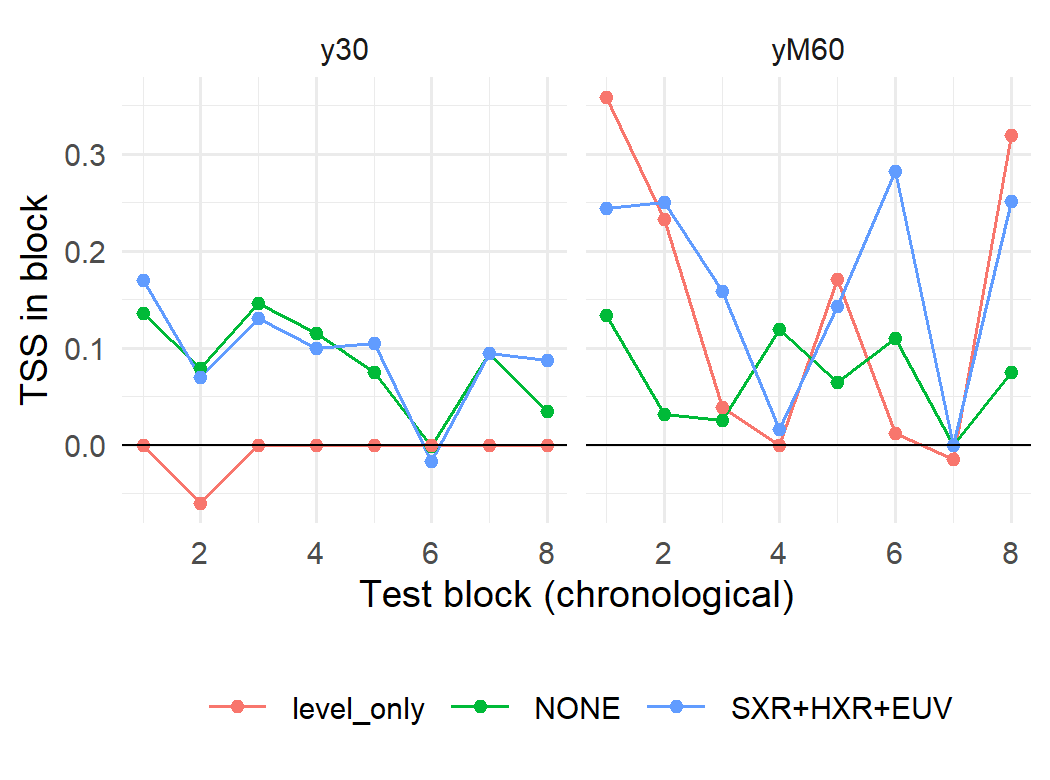

In [12]:
pb = load("per_block_tss.csv")
if pb is not None:
    x = pb[(pb.model=="glmnet") & pb.target.isin(["yM30","yM60"]) & pb.subset.isin(["level_only","NONE","SXR+HXR+EUV"])].pivot_table(index=["target","fold"], columns="subset", values="TSS").round(2)
    display(x)
    print("blocks where level-only >= history-only:", int((x.level_only >= x.NONE).sum()), "of", len(x))
show_png(FG/"fig_per_block_tss.png", 520)

Under leave-one-block-out the single-feature baseline looks stable in many blocks. **But that evaluation lets the model learn from later periods.** The real test is forward in time:

In [13]:
fw2 = load("forward_vs_loo_pooled.csv")
if fw2 is not None:
    lv = fw2[fw2.subset.isin(["level_only","NONE","SXR+HXR+EUV"])].groupby(["subset","target"])[["TSS_loo","TSS_forward"]].mean().round(3).unstack("subset")
    display(lv.reindex(["y15","y30","y60","yM30","yM60"]))

TSS_loo                        TSS_forward                       
subset    NONE SXR+HXR+EUV level_only        NONE SXR+HXR+EUV level_only
target                                                                  
y15      0.105       0.148      0.009       0.031       0.067      0.054
y30      0.133       0.123     -0.042       0.092       0.072      0.000
y60      0.139       0.139     -0.044       0.098       0.073      0.000
yM30     0.322       0.342      0.323       0.202       0.149      0.003
yM60     0.286       0.328      0.323       0.198       0.251      0.024

> **BAD DECISION / MISTAKE.** The SoLEXS-level-only baseline, which seemed to match every model for M+ flares, **falls to about zero when evaluated forward in time** (compare the two columns). So its apparent strength was largely an artefact of letting the model see later periods. We would have kept believing in a "persistence explains M+ skill" story if the forward test had not been added. The paper now says the result does *not* survive the realistic evaluation.

Why it fails forward: during the later blocks the Sun's activity level differs from the earlier ones, so a threshold on the *absolute* soft X-ray level learned from one regime transfers poorly to another. This is exactly the non-stationarity warned about in the limitations.

> **NOTE.** A tempting explanation (which turned out to be only partly right, see below): M-class flares come from large, bright active regions, and a high *current* soft X-ray background means such a region is on the disk. The level alone says "a big region is active", which is most of what you need to know for rare M+ events. For C-class flares (which occur in almost any active region) the level says little. Under leave-one-block-out this looks like a **persistence effect**; the forward-in-time test below shows how fragile it is.

## Two ways to measure "does a band help beyond history?" and why they disagree
* **Pooled estimate:** pool all test predictions, compute TSS once. Rows are weighted equally.
* **Paired-block estimate:** compute the improvement within each of the 8 blocks (each is a separate refit and a disjoint period), then average. Blocks are weighted equally.

In [14]:
pa = load("paired_block_summary_by_subset.csv"); dl = load("delta_vs_history.csv")
if pa is not None and dl is not None:
    pooled = dl.groupby("subset").delta_vs_history.mean().rename("pooled mean gain")
    both = pa.set_index("subset")[["mean_delta","ci_above0","ci_below0","blocks_pos"]].join(pooled)
    both.columns = ["paired-block mean gain","# of 15 with CI>0","# of 15 with CI<0","fraction of blocks positive","pooled mean gain"]
    display(both.round(3))

,paired-block mean gain,# of 15 with CI>0,# of 15 with CI<0,fraction of blocks positive,pooled mean gain
subset,,,,,
SXR,0.067,7,0,0.758,0.039
HXR,0.021,4,1,0.467,0.009
EUV,0.028,3,0,0.508,-0.004
SXR+HXR,0.074,7,0,0.750,0.054
SXR+EUV,0.069,8,0,0.667,0.020
HXR+EUV,0.032,4,0,0.558,0.009
SXR+HXR+EUV,0.073,7,0,0.700,0.035


The paired-block gains are larger than the pooled ones (about 0.07 vs 0.02 to 0.05 for SXR-containing sets). Both are legitimate and they weight the data differently. The honest statement: **SXR-containing sets beat history by roughly 0.02 to 0.07 TSS depending on the estimator, and HXR or EUV alone add far less**. The paper reports both.

> **BAD DECISION / MISTAKE.** In the first draft we only reported the pooled estimate, which was the *less favourable* one. That was accidental, not cherry-picking, but it shows why you should compute your result more than one way before deciding what to claim.

# Chapter 9. Shapley values: giving each band a fair share

## 9.1 The idea
Three bands, eight possible subsets. If we say "SXR is worth +0.03", it depends on what else is already in the model. The **Shapley value** answers fairly: *average the marginal gain of a band over every order in which bands could be added.*

## 9.2 A worked example with the real numbers
Take one target and one model, and take the actual pooled TSS of each subset.

In [15]:
from itertools import combinations
from math import factorial
dd = load("results.csv"); T, M = "y30", "xgboost"
v = {s: float(dd[(dd.target==T)&(dd.model==M)&(dd.subset==s)].TSS.iloc[0]) for s in ["NONE","SXR","HXR","EUV","SXR+HXR","SXR+EUV","HXR+EUV","SXR+HXR+EUV"]}
def key(S): return "+".join([b for b in ["SXR","HXR","EUV"] if b in S]) or "NONE"
players = ["SXR","HXR","EUV"]; phi = {}
for i in players:
    others = [p for p in players if p != i]; tot = 0
    for k in range(len(others)+1):
        for S in combinations(others, k):
            w = factorial(len(S))*factorial(len(players)-len(S)-1)/factorial(len(players)); tot += w*(v[key(set(S)|{i})] - v[key(set(S))])
    phi[i] = tot
print({k: round(x,3) for k,x in v.items()})
print("Shapley (hand-computed):", {k: round(x,3) for k,x in phi.items()})
print("sum of Shapley values =", round(sum(phi.values()),3), "  = v(all) - v(history only) =", round(v["SXR+HXR+EUV"]-v["NONE"],3))
saved = load("shapley_band_contribution.csv"); print("saved by the pipeline:", saved[(saved.target==T)&(saved.model==M)][["band","shapley_TSS"]].round(3).to_dict("records"))

{'NONE': 0.127, 'SXR': 0.134, 'HXR': 0.102, 'EUV': 0.105, 'SXR+HXR': 0.164, 'SXR+EUV': 0.118, 'HXR+EUV': 0.114, 'SXR+HXR+EUV': 0.138}
Shapley (hand-computed): {'SXR': 0.023, 'HXR': 0.005, 'EUV': -0.017}
sum of Shapley values = 0.011   = v(all) - v(history only) = 0.011


saved by the pipeline: [{'band': 'SXR', 'shapley_TSS': 0.023}, {'band': 'HXR', 'shapley_TSS': 0.005}, {'band': 'EUV', 'shapley_TSS': -0.017}]


The hand computation matches the pipeline, and the three values **add up exactly** to (full model) minus (history only). That is the Shapley guarantee, and a handy check that the code is right.

## 9.3 The uncertainty, and what it does not cover
Confidence intervals come from a **block bootstrap** (resample 6-hour blocks of the pooled test predictions 500 times). It captures *"what if the test period had been a different sample of solar activity"*. It does **not** capture *"what if we had trained the models on different data"*, because the models are held fixed.

> **BAD DECISION / MISTAKE.** The paper's tables show "mean ± SD" across the three model families. That SD is a *spread between algorithms*, not a confidence interval, and the first draft's wording blurred this. A reviewer caught it. It is now stated explicitly.

> **NOTE.** Across 105 band-subset comparisons against history, 27 have an interval above zero. That is far more than chance would give, but the comparisons are not independent and there is **no multiple-comparison correction**, so we call the study **exploratory**, not confirmatory.

In [16]:
cs = load("shapley_consensus.csv"); cs.pivot(index="target", columns="band", values="shapley_mean").round(3).loc[["y15","y30","y60","yM30","yM60"]]

band,EUV,HXR,SXR
target,,,
y15,0.017,0.004,0.023
y30,-0.017,0.012,0.026
y60,-0.012,0.023,0.023
yM30,-0.033,0.012,0.043
yM60,-0.009,0.012,0.050


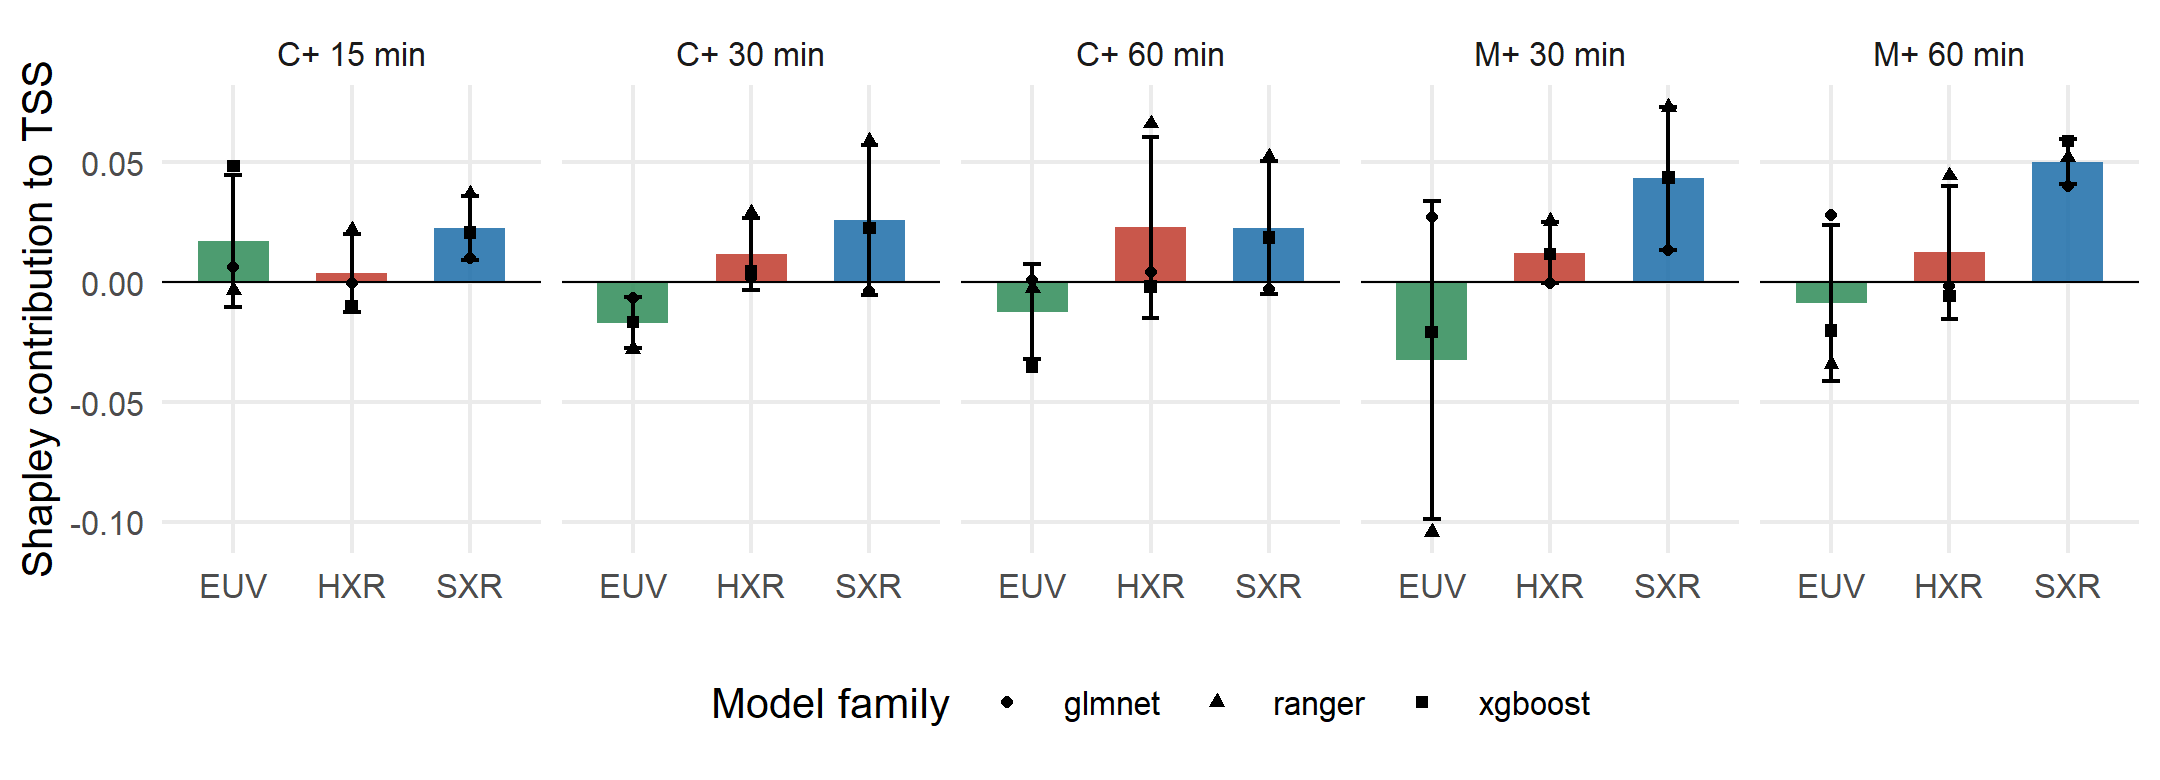

In [17]:
show_png(FG/"fig_shapley_bands.png", 760)

# Chapter 10. Nowcasting: where hard X-rays shine

## 10.1 The Neupert test on the real data
For each M or X flare we correlate, during the rise phase, the HEL1OS 20 to 40 keV rate with the *change* in SoLEXS counts. If the Neupert effect holds, the correlation is positive.

flares:

 172 | median rank correlation: 0.39 | fraction positive: 0.94


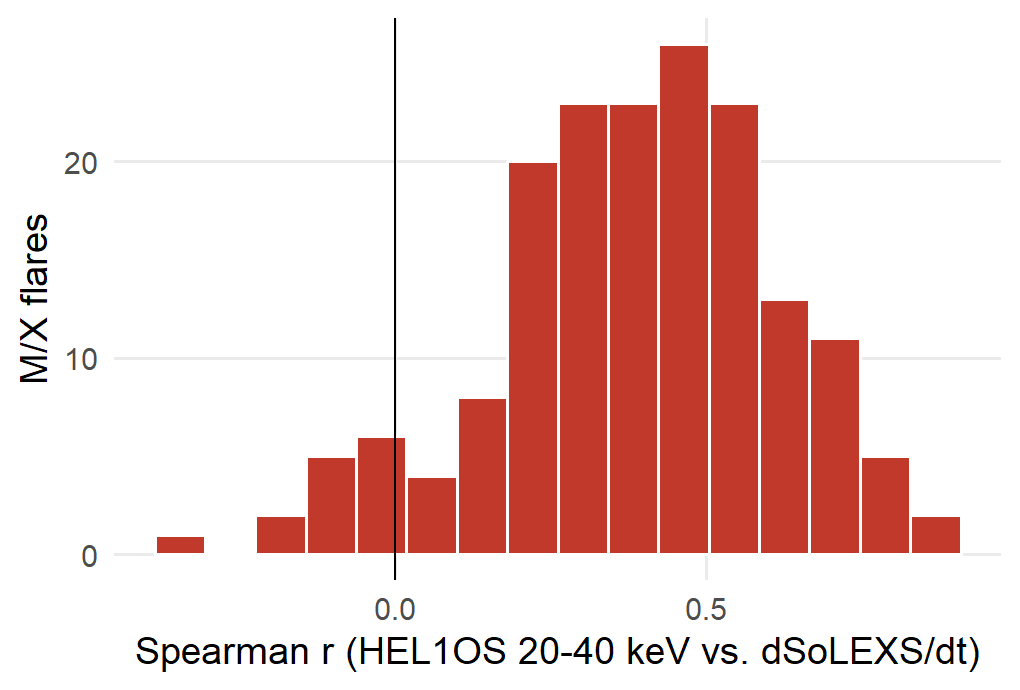

In [18]:
np_ = load("neupert_per_flare_spearman.csv")
print("flares:", len(np_), "| median rank correlation:", round(np_.r.median(), 2), "| fraction positive:", round((np_.r > 0).mean(), 2))
show_png(FG/"fig_neupert.png", 440)

## 10.2 Which band registers a flare first?
Detection rule (per band): a robust z-score of the log rate against the preceding three hours; "detected" at the first minute with z > 5 for two consecutive minutes, between 20 minutes before the NOAA start and the peak. Latency is *detection time minus NOAA start* (positive = after).

,class_group,band,n,detected,median_latency_min,q25,q75
0,C,SoLEXS (SXR),443,0.35,6.0,3.00,7.0
1,C,HEL1OS 20-40 keV,443,0.06,4.5,2.25,6.0
2,C,HEL1OS 60-150 keV,443,0.01,0.0,-13.00,5.0
3,C,GOES EUV 30.4 nm,437,0.00,NaN,NaN,NaN
4,M/X,SoLEXS (SXR),169,0.59,6.0,3.00,8.0
5,M/X,HEL1OS 20-40 keV,169,0.57,5.0,3.00,7.0
6,M/X,HEL1OS 60-150 keV,169,0.15,7.0,4.00,8.0
7,M/X,GOES EUV 30.4 nm,167,0.01,7.0,7.00,7.0


,class_group,n_both,median_diff_min,hel_earlier,same_minute,hel_later
0,M/X,65,-1,0.52,0.31,0.17
1,C,14,-1,0.57,0.14,0.29


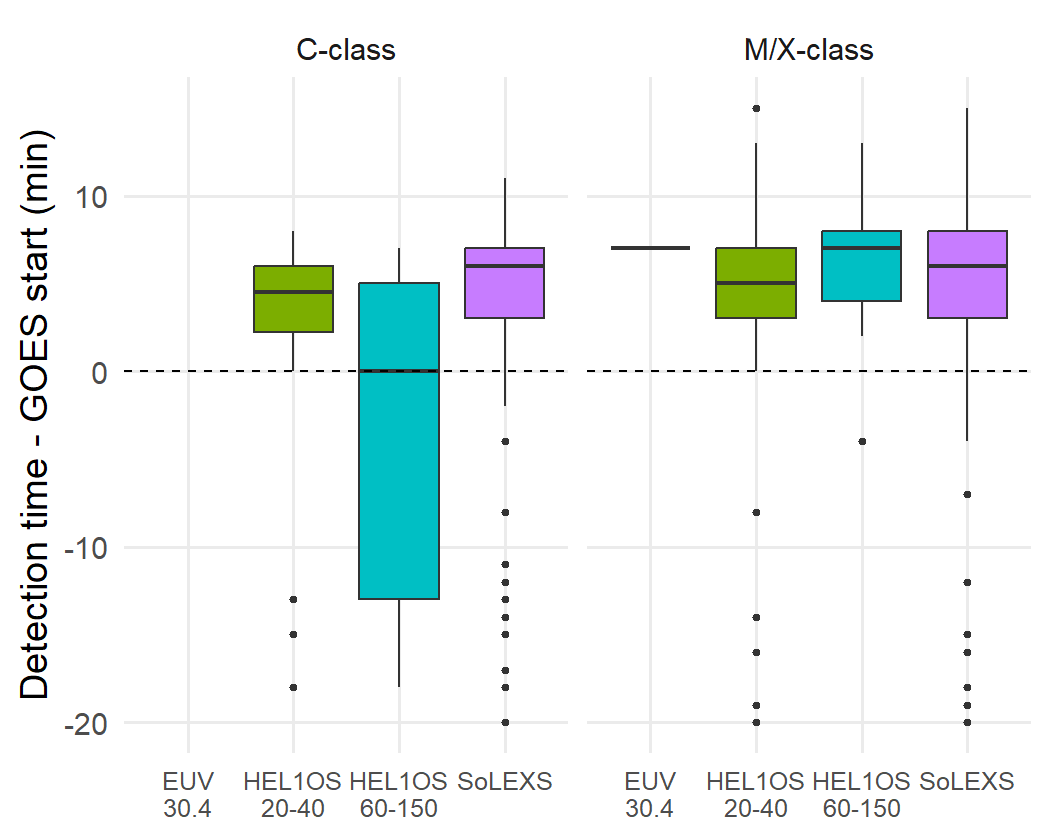

In [19]:
nl = load("nowcast_latency_summary.csv"); display(nl.round(2)); pw = load("nowcast_paired.csv"); display(pw.round(2)); show_png(FG/"fig_nowcast_latency.png", 520)

**Honest summary.** For M/X flares SoLEXS and HEL1OS (20 to 40 keV) detect about the same share. When both detect the same flare, HEL1OS is typically a minute earlier. EUV at 1-minute cadence essentially never crosses the threshold, and for C-class flares only SoLEXS detects a decent share.

> **BAD DECISION / MISTAKE.** It is tempting to describe "one minute earlier" as "extra warning". It is not: it is a **nowcasting** gain on flares already detected by both instruments, measured against NOAA's own start definition (which itself lags the true onset). A reviewer flagged this conflation between nowcasting and forecasting. The paper now separates them clearly.

# Chapter 11. What would alerts actually look like?

TSS is a *per-minute* score. A user cares about *alerts*: how many per day, and how many are followed by a flare. We merge alert minutes separated by at most 5 minutes into **episodes**, and count an episode as correct if a flare starts within the horizon after it.

In [20]:
al = load("alert_episode_metrics.csv")
if al is not None:
    s = al[(al.model=="xgboost") & al.subset.isin(["NONE","SXR+HXR+EUV"])][["target","subset","episodes_per_day","episode_precision","flare_detect_rate","alert_minute_share"]].round(2)
    display(s.sort_values(["target","subset"]).reset_index(drop=True))

,target,subset,episodes_per_day,episode_precision,flare_detect_rate,alert_minute_share
0,y15,NONE,6.45,0.72,0.35,0.37
1,y15,SXR+HXR+EUV,27.33,0.26,0.50,0.33
2,y30,NONE,5.88,0.76,0.34,0.31
3,y30,SXR+HXR+EUV,19.44,0.38,0.49,0.29
4,y60,NONE,5.81,0.85,0.38,0.35
5,y60,SXR+HXR+EUV,15.96,0.52,0.50,0.33
6,yM30,NONE,5.56,0.37,0.54,0.34
7,yM30,SXR+HXR+EUV,10.15,0.21,0.57,0.27
8,yM60,NONE,6.24,0.39,0.57,0.41
9,yM60,SXR+HXR+EUV,10.40,0.25,0.57,0.30


Read the last column carefully: the TSS-optimal threshold keeps the alert **switched on about a third of all minutes**. The full model raises many more episodes per day than the history-only model, and a much lower share of them are followed by a flare, but it catches more flares.

> **BAD DECISION / MISTAKE.** The first draft only said "false-alarm ratios are high". This table shows the operational reality is *much worse than that phrase suggests*. A threshold that maximises TSS is not a threshold anyone would deploy, and optimising for fewer alerts would be a separate study.

# Chapter 12. Robustness: does the answer survive other choices?

## 12.1 Including the particle-contaminated periods
The HEL1OS SEP catalog lists periods when energetic particles raise the hard X-ray background. We *excluded* four such periods (about 12 days) from the main run, then reran with them *included*.

In [21]:
sp = load("sensitivity_sep.csv");
if sp is not None: display(sp.round(3).head(12))
sh = load("shapley_consensus.csv", ROOT/"outputs_adl1_sepincl"/"tables")
if sh is not None: print("with SEP included, Shapley ranges per band:", sh.groupby("band").shapley_mean.agg(["min","max"]).round(3).to_dict("index"))

,target,subset,TSS_excl,TSS_incl
0,y15,NONE,0.111,0.120
1,y15,SXR+HXR+EUV,0.149,0.134
2,y30,NONE,0.137,0.106
3,y30,SXR+HXR+EUV,0.138,0.126
4,y60,NONE,0.147,0.129
5,y60,SXR+HXR+EUV,0.140,0.147
6,yM30,NONE,0.298,0.258
7,yM30,SXR+HXR+EUV,0.336,0.343
8,yM60,NONE,0.289,0.268
9,yM60,SXR+HXR+EUV,0.339,0.304


with SEP included, Shapley ranges per band: {'EUV': {'min': -0.01, 'max': 0.024}, 'HXR': {'min': -0.018, 'max': 0.008}, 'SXR': {'min': 0.016, 'max': 0.06}}


> **GOOD DECISION.** The conclusion does not depend on the SEP choice: the pooled TSS moves by about 0.015 on average and the band ordering is unchanged.

## 12.2 The earlier (preliminary) study
Before the Aditya-L1 data arrived we built the whole pipeline on Fermi GBM hard X-rays (21 days, May 2024). Its first version used a **single chronological split**, and the test set held only about 25 flares. Every confidence interval overlapped zero, so it told us nothing.

> **GOOD DECISION.** Recognising that "nothing significant" meant *too little test data*, not *no effect*, we switched to blocked cross-validation over the whole period, which multiplied the test flares about five-fold. That change is the reason the final design looks the way it does.

> **BAD DECISION / MISTAKE.** Part of the first Fermi run produced results from a pipeline that never had a flare-history baseline, which made the band contributions look larger than they are. The Aditya-L1 study added it.

# Chapter 13. A critical review of our own paper, and our response

An external reviewer read the finished 5-page paper. The table below pairs each criticism with what we found and did.

| Criticism | Verdict | Action |
|---|---|---|
| Window too short, mostly one phase of the cycle | **True** | cannot fix without more data; stated plainly as the main limitation; added per-block and forward-chaining checks |
| Uncertainty ignores model refitting; multiple comparisons | **True** | added paired-block analysis (each block is a fresh refit); labelled everything *exploratory*; clarified what the "±" means |
| Possible leakage in features | **Plausible to worry; now tested** | added an automated causality test (and fixed the test that had initially passed vacuously) |
| Validation not forward in time | **True** | added forward-chaining evaluation |
| Event-level evaluation unclear; false alarms | **True** | added alert-episode metrics (episodes/day, precision, alert duty cycle) |
| Title conflates forecasting and nowcasting | **Partly true** | abstract/discussion now separate the two; forecasting is the main claim, latency is a separate nowcasting analysis |
| Short reference list, no stated research gap | **True** | targeted literature search, verified citations, explicit gap statement |
| "SoLEXS-level-only" baseline suspicious | **Reasonable to check** | checked identical protocol and per-block stability; explained physically (persistence) |
| Cites a Fermi analysis without a reference | **True** | now cited as supplementary material |

> **GOOD DECISION.** Treating a harsh review as a to-do list, and *fixing the test before trusting the fix*, produced a visibly better paper.

# Chapter 14. The decision log, all in one place

### Good decisions (keep doing these)
1. **A contribution question, not a leaderboard question.** (Ch. 1)
2. **Public proxy data first** so the pipeline existed before the real data arrived. (Ch. 3)
3. **Missing data stays missing.** No silent interpolation. (Ch. 4)
4. **Forecast starts, not occurrence, and exclude ongoing flares.** (Ch. 5)
5. **Flare history in every model** so bands are measured beyond free information. (Ch. 5)
6. **Blocked CV, purge gaps, thresholds on separate validation data.** (Ch. 6)
7. **Three model families + consensus**, not one lucky model. (Ch. 7, 9)
8. **Exact Shapley values**, verified to sum to the total gain. (Ch. 9)
9. **SEP periods excluded, then included as a sensitivity run.** (Ch. 12)
10. **Reading the generated download script before running it.** (Ch. 3)
11. **Reporting a modest, honest result** and listing limitations instead of overselling. (throughout)

### Bad decisions / mistakes (and the cost)
| Mistake | Cost | Lesson |
|---|---|---|
| Planned big downloads before measuring speed | hours; scope repeatedly shrunk | measure first |
| Accepted downloads by "size > 0" | 21 corrupt files found much later | verify integrity |
| Silent error handling in parallel jobs | a full hour of compute wasted | never swallow errors |
| Integer overflow in the score | the whole first model run lost | test at realistic size |
| A causality test that could not fail | false confidence | check a pass actually tested something |
| Single chronological split on 3 weeks | nothing significant; weeks of confusion | check test-set size before interpreting |
| Reported only the pooled estimate | understated the SXR gain | compute results two ways |
| "High false-alarm ratio" as the only alert statement | hid a ~30% alert duty cycle | measure what the user would experience |
| Validation direction not stated | reviewer caught it | state exactly what the model is allowed to see |
| Over-escaped backslashes corrupted LaTeX twice | an hour of debugging | edit generated files with the right tool, check the file |

### What we would do next
* Much longer baseline (a year or more), several active regions, a held-out *later* period.
* Add SDO/HMI magnetic features, to measure each radiation band on top of a state-of-the-art forecaster.
* Use native 1-second HXR for sub-minute precursor bursts.
* Calibrated probabilities and an alert policy chosen for a target false-alarm rate, not for maximum TSS.
* Retrain-and-bootstrap uncertainty to include refit variance.

# Chapter 15. How to reproduce everything, and a glossary

## Reproduction order
1. `scripts_py/preprocess_aditya.py` : nested zips to `data/processed_adl1/solexs_1min.csv`, `hel1os_1min.csv`
2. `R/02_clean_align.R` (GOES, with `SOLAR_RAW`, `SOLAR_PROC`)
3. `R/10_features_adl1.R` : features, labels, flare history
4. `R/11_models_adl1.R` (`MODE=forward` for the forward-chaining run)
5. `R/12_attribution_adl1.R` : Shapley values and bootstrap
6. `R/13_eda_nowcast_adl1.R` : Neupert and detection latency
7. `R/15_causality_test.R`, `R/16_robustness_adl1.R`
8. `R/14_paper_assets.R` then compile `paper/ieee/main.tex`
9. `python notebook/build_textbook.py` : this notebook

## Glossary
**SXR/HXR/EUV**: soft X-ray / hard X-ray / extreme ultraviolet. **SoLEXS/HEL1OS**: Aditya-L1 soft and hard X-ray spectrometers. **GOES class**: B < C < M < X by peak soft X-ray flux. **TSS**: True Skill Statistic. **POD / POFD / FAR**: probability of detection / of false detection / false-alarm ratio. **Blocked CV**: cross-validation using contiguous time blocks. **Purge gap**: data removed around a boundary to prevent leakage. **Forward chaining**: training only on the past. **Shapley value**: a feature's average marginal contribution over all orderings. **Bootstrap**: resampling to estimate uncertainty. **SEP**: solar energetic particles. **Neupert effect**: HXR resembles the derivative of SXR. **Nowcasting vs forecasting**: detecting an ongoing flare vs predicting one that has not started.

# PART 2: Round 2 (6 months of data, magnetic features, a stronger baseline)

Chapters 1 to 15 tell the story of **round 1**: about two months of Aditya-L1 data. After a harsh review and a sober look at the results, we decided to make the study stronger. This part tells that story, including the new mistakes.

# Chapter 16. What we set out to fix, and what we chose not to

The review left three limitations that more work could address:

| Limitation | Plan | Decision |
|---|---|---|
| Only ~2 months of data | **A**: extend to 6 months (1 Jul to 31 Dec 2024) | do it |
| No magnetic-field information | **B**: add SDO/HMI magnetic features | do it |
| Weak literature review, unclear novelty | **D**: proper literature search and rewrite | do it |
| Only one phase of the solar cycle | **C**: add months from 2025 and 2026 | **skip** (about 15 GB more, days of work) |

> **GOOD DECISION.** Skipping C was a deliberate trade-off, not an oversight. It means the paper still says "one phase of the solar cycle" under limitations.

## 16.1 The extra data
Aditya-L1 data exists on PRADAN from July 2024. We downloaded July to September for SoLEXS (79 days) and HEL1OS (188 twelve-hour files, about 8 GB), plus the matching GOES files. Two things went wrong on the way and are worth remembering:

* **The login session expired** between sessions. PRADAN showed its login page. An assistant must never type your password, so the work paused until you logged in yourself.
  > **GOOD DECISION.** Credentials are never delegated. Pausing cost minutes; guessing around it would have cost trust.
* **NOAA's server dropped 167 of 243 GOES files** in the first attempt (it did this earlier too). The downloader is resumable, so three retries recovered everything. All 37 "missing" EUV days did exist on the server; they had only failed in transit.
  > **BAD DECISION / MISTAKE.** We trusted "download complete" in a log, and it was true only in the sense that the script had finished. Counting files per day against the calendar caught the gap.

In [22]:
OUT2 = ROOT / "outputs_v2"; TB2 = OUT2 / "tables"; PROC2 = ROOT / "data" / "processed_v2"
f6 = PROC2 / "features_v2.csv"
if f6.exists():
    ff = pd.read_csv(f6, usecols=["time","complete","sep","ongoing","y15","y30","y60","yM30","yM60"], parse_dates=["time"])
    u6 = ff[(ff.complete) & (~ff.sep)]
    print("window:", ff.time.min(), "->", ff.time.max(), "| minutes:", len(ff), "| usable:", len(u6), "= about", round(len(u6)/1440), "days of full coverage")
    print("round 1 usable minutes: 87,245 (about 61 days)  ->  round 2: about", format(len(u6), ","))
    ev6 = pd.read_csv(PROC2/"flare_events.csv"); print("flares in the GOES list for the period:", len(ev6))
else: print("round-2 features not built yet")

window: 2024-07-01 00:02:00+00:00 -> 2024-12-30 23:59:00+00:00 | minutes: 263518 | usable: 158191 = about 110 days of full coverage
round 1 usable minutes: 87,245 (about 61 days)  ->  round 2: about 158,191
flares in the GOES list for the period: 1607


# Chapter 17. Magnetic features, and what they were worth

## 17.1 Where they come from
The Sun's flares are driven by its magnetic field, and the SDO/HMI instrument measures it. Its **SHARP** data product summarises each active region with numbers (total unsigned magnetic flux, total current helicity, free-energy proxy, a complexity index called R-value, and others). Crucially, the JSOC data centre serves these as **small tables of numbers**, not images, and the keyword service needed no download of big files.

We pulled about 346,000 region-records at 12-minute cadence for 184 days (a few MB in total), then reduced them to **full-disk summaries**: for each time step, the total flux over all good-quality regions within 60 degrees of the central meridian, the largest R-value, the number of regions, and so on.

> **GOOD DECISION.** Full-disk summaries avoided the hard problem of matching each flare to a specific active region. The cost is that they are crude: they say "how magnetically busy is the Sun", not "which region is about to flare".

> **GOOD DECISION.** Timing is causal: a value is only usable 12 minutes after its observation time, carried forward at most an hour, and 6-hour and 24-hour changes use only earlier values. The causality test (Chapter 5) was rerun on the new 92-feature table and passed.

## 17.2 Two bugs in the magnetic pipeline

In [23]:
# bug 1: the quality flag is a hex *string*, e.g. "0x00000000". A filter written for numbers matched NOTHING and produced an empty table.
q = "0x00000000"
try: print("float(q) ->", float(q))
except Exception as e: print("float('0x00000000') fails:", e)
print("int(q, 16) ->", int(q, 16), " (0 means good quality)")

float('0x00000000') fails: could not convert string to float: '0x00000000'
int(q, 16) -> 0  (0 means good quality)


> **BAD DECISION / MISTAKE.** **Bug 1 (hex quality flag):** the aggregation step silently wrote an empty file, and only an explicit "how many rows did we get" check showed it. One day (3 August) also failed to download and was re-fetched.

> **BAD DECISION / MISTAKE.** **Bug 2 (the column-name prefix):** when building the feature table, a named list passed to `cbind` prefixed every column name (for example `sxr.sxr_sol_log`). The rest of the script looked for columns starting with `sxr_`, found **none**, and then computed the "all features present" flag over **zero columns**. Every minute therefore counted as "complete": usable rows jumped from about 97,000 to 131,000, which looked like good news. It was a bug.

How it was caught: we compared the new table with the old one column by column (NA shares, value differences) before trusting it. After the fix the two agreed to within CSV rounding (maximum difference 0.0009), and we added a guard so that this can never silently happen again (the script now stops if fewer than 50 feature columns are found). **A result that looks too good is a reason to look harder.**

## 17.3 The hard X-ray "1-second" data is really 8-second data
Planning to test the hypothesis that sub-minute hard X-ray bursts are precursors, we looked at the native 1-second HEL1OS light curve. It was not what it seemed.

In [24]:
import zipfile, glob, io
from astropy.io import fits
fh = glob.glob(r"C:\solar-data\aditya\hel1os\**\HLS_20241212_000*_V*.zip", recursive=True)
if fh:
    z = zipfile.ZipFile(fh[0]); h = fits.open(io.BytesIO(z.read([n for n in z.namelist() if n.endswith("lightcurve_czt1.fits")][0])))
    ext = [x for x in h if x.name.startswith("CZT1_LC_BAND_20")][0]; d = ext.data
    t = (np.asarray(d["MJD"]) - 40587) * 86400; r = np.asarray(d["CTR"], float); e = np.asarray(d["STAT_ERR"], float); nz = r > 0
    print("fraction of 1 s samples equal to zero:", round(float((r == 0).mean()), 3))
    print("median spacing between non-zero readings (s):", float(np.median(np.diff(t[nz]))))
    print("CTR / STAT_ERR^2 for non-zero readings (1.0 means CTR is a raw COUNT):", round(float(np.median(r[nz] / e[nz]**2)), 3))
    print("first 24 samples:", [int(x) for x in r[:24]])

fraction of 1 s samples equal to zero: 0.834
median spacing between non-zero readings (s): 7.000000238418579
CTR / STAT_ERR^2 for non-zero readings (1.0 means CTR is a raw COUNT): 1.0
first 24 samples: [187, 0, 0, 0, 0, 0, 0, 0, 130, 0, 0, 0, 0, 0, 0, 0, 72, 0, 0, 0, 0, 0, 0, 0]


The detector delivers **one reading about every 8 seconds**; the other seven 1-second slots are zero. The values are raw counts (the error equals the square root of the value), not rates. Three consequences:

1. **The one-minute averages we used all along are correct** (sum of counts divided by 60 s gives counts per second), so no earlier result changes.
2. "Native 1-second hard X-ray features" would have measured the **readout cycle**, not the Sun. A first version of the sub-minute features gave *identical* burst counts in two different energy bands, which was the clue.
3. The honest sub-minute resolution is **about 8 seconds**. The new features are built on 8-second blocks (peak 8-second rate, variability, and a count of blocks above a Poisson threshold).

> **BAD DECISION / MISTAKE.** Our own plan, repeated in an earlier answer and in the paper's Future Work, assumed a 1-second cadence. We checked the file header and the data before building on it. The paper now says "about 8 s readout". Always read the instrument documentation *and* look at the raw numbers.

# Chapter 18. Round 2 results

## 18.1 The new baseline
Every band configuration now includes **flare history and magnetic state**; the bands are measured *beyond both*. We also keep a **history only (no magnetic)** model, so the value of the magnetic features themselves can be read off directly.

In [25]:
R2 = load("results.csv", TB2)
if R2 is not None:
    order2 = ["NONE","SXR","HXR","EUV","SXR+HXR","SXR+EUV","HXR+EUV","SXR+HXR+EUV","HISTONLY","level_only"]
    lab2 = ["history + magnetic","+SXR","+HXR","+EUV","+SXR+HXR","+SXR+EUV","+HXR+EUV","+all three","history only (no magnetic)","SoLEXS level only"]
    t = R2.pivot_table(index="subset", columns="target", values="TSS", aggfunc="mean").reindex(order2)[["y15","y30","y60","yM30","yM60"]].round(3)
    t.columns = ["C+ 15","C+ 30","C+ 60","M+ 30","M+ 60"]; t.index = lab2
    print("Round 2, leave-one-block-out, pooled TSS (mean of model families)"); display(t)
else: print("round-2 results not available yet")

Round 2, leave-one-block-out, pooled TSS (mean of model families)


,C+ 15,C+ 30,C+ 60,M+ 30,M+ 60
history + magnetic,0.059,0.052,0.054,0.158,0.178
+SXR,0.097,0.083,0.060,0.224,0.246
+HXR,0.058,0.056,0.060,0.170,0.179
+EUV,0.097,0.088,0.070,0.187,0.157
+SXR+HXR,0.094,0.075,0.062,0.231,0.230
+SXR+EUV,0.103,0.102,0.066,0.226,0.236
+HXR+EUV,0.085,0.069,0.069,0.184,0.155
+all three,0.090,0.076,0.079,0.229,0.224
history only (no magnetic),0.052,0.053,0.050,0.166,0.174
SoLEXS level only,0.032,0.027,0.017,0.273,0.285


In [26]:
fw2 = load("forward_vs_loo_pooled.csv", TB2)
if fw2 is not None:
    s2 = fw2.groupby("subset")[["TSS_loo","TSS_forward","diff"]].mean().round(3)
    print("Same test blocks (3 to 8): leave-one-block-out vs forward in time"); display(s2)
    print("mean change when testing forward in time:", round(fw2["diff"].mean(), 3), "| share of configurations that get worse:", round(float((fw2["diff"] < 0).mean()), 2))
    mg = fw2[fw2.subset == "NONE"][["TSS_loo","TSS_forward"]].mean() - fw2[fw2.subset == "HISTONLY"][["TSS_loo","TSS_forward"]].mean()
    print("what the magnetic features add (history+magnetic minus history only): LOO", round(float(mg.TSS_loo), 3), "| forward", round(float(mg.TSS_forward), 3))

Same test blocks (3 to 8): leave-one-block-out vs forward in time


,TSS_loo,TSS_forward,diff
subset,,,
EUV,0.157,0.139,-0.018
HISTONLY,0.155,0.137,-0.018
HXR,0.147,0.125,-0.022
HXR+EUV,0.160,0.140,-0.020
NONE,0.148,0.133,-0.015
SXR,0.198,0.165,-0.033
SXR+EUV,0.199,0.162,-0.037
SXR+HXR,0.194,0.179,-0.015
SXR+HXR+EUV,0.194,0.164,-0.030


mean change when testing forward in time: -0.023 | share of configurations that get worse: 0.78
what the magnetic features add (history+magnetic minus history only): LOO -0.006 | forward -0.004


In [27]:
pb2 = load("paired_block_summary_by_subset.csv", TB2); fa2 = load("forward_paired_block_vs_history.csv", TB2)
if pb2 is not None and fa2 is not None:
    fs2 = fa2.groupby("subset").agg(forward_mean_gain=("mean_delta","mean"), forward_intervals_above0=("lo", lambda x: int((x > 0).sum())), n=("lo","size"))
    both2 = pb2.set_index("subset")[["mean_delta","ci_above0","n"]].rename(columns={"mean_delta":"LOO_mean_gain","ci_above0":"LOO_intervals_above0","n":"LOO_n"}).join(fs2)
    print("Gain over the history + magnetic baseline, paired test blocks"); display(both2.round(3))
cs2 = load("shapley_consensus.csv", TB2); csf2 = load("shapley_consensus.csv", ROOT/"outputs_v2_forward"/"tables")
if cs2 is not None and csf2 is not None:
    m2 = cs2.pivot(index="target", columns="band", values="shapley_mean").round(3).add_suffix(" (LOO)").join(csf2.pivot(index="target", columns="band", values="shapley_mean").round(3).add_suffix(" (forward)"))
    print("Shapley contribution of each band beyond history + magnetic"); display(m2.loc[["y15","y30","y60","yM30","yM60"]])

Gain over the history + magnetic baseline, paired test blocks


,LOO_mean_gain,LOO_intervals_above0,LOO_n,forward_mean_gain,forward_intervals_above0,n
subset,,,,,,
SXR,0.044,10,15,0.046,0.0,10.0
HXR,0.003,0,15,0.001,0.0,10.0
EUV,0.012,3,15,0.004,0.0,10.0
SXR+HXR,0.041,9,15,0.052,2.0,10.0
SXR+EUV,0.047,9,15,0.036,2.0,10.0
HXR+EUV,0.013,1,15,-0.001,0.0,10.0
SXR+HXR+EUV,0.043,8,15,0.039,1.0,10.0
HISTONLY,0.008,2,15,NaN,NaN,NaN


Shapley contribution of each band beyond history + magnetic


band,EUV (LOO),HXR (LOO),SXR (LOO),EUV (forward),HXR (forward),SXR (forward)
target,,,,,,
y15,0.016,-0.007,0.021,0.004,0.001,0.029
y30,0.018,-0.012,0.018,0.005,-0.002,0.009
y60,0.013,0.007,0.005,-0.024,0.008,-0.013
yM30,0.012,0.006,0.054,0.011,-0.005,0.068
yM60,-0.015,-0.007,0.068,-0.002,-0.000,0.065


## 18.2 How to read round 2 (fill in from the tables above)
* **Were the magnetic features useful?** Compare "history + magnetic" with "history only" in the table. In the interim two-month run they were not: the difference was within noise. Full-disk summaries are crude, so this does not say magnetic data is useless; it says *these* summaries added nothing here.
* **Did more data change the picture?** Look at how many forward-in-time intervals now sit above zero, and how the forward and leave-one-block-out numbers compare. More data narrows the intervals; it does not guarantee a different conclusion.
* **Did the sub-minute hard X-ray features help?** Compare "+HXR" with the baseline, and "+SXR+HXR" with "+SXR".

> **NOTE.** Whatever the tables say is what goes in the paper. We did not choose the analysis to get a particular answer.

# Chapter 19. The decision log, updated

### New good decisions in round 2
* Skipping the optional extra months (plan C) and saying so openly.
* Magnetic data as *small keyword tables* via JSOC, aggregated to full-disk summaries with a causal 12-minute delay.
* **Verifying the new feature table against the old one** before using it, which exposed the column-name bug.
* A guard (`stopifnot`) that makes the "zero feature columns" failure impossible to repeat.
* Re-checking the HEL1OS file header and raw numbers before building on the "1 second" assumption.
* Keeping round 1 intact (`outputs_adl1`) so round 2 can be compared against it.
* Removing the `pandas` dependency from the new preprocessing, after Windows' Application Control began blocking it. We did not try to bypass the security policy.

### New mistakes (and the cost)
| Mistake | Cost | Lesson |
|---|---|---|
| Hex quality flag read as a number | empty magnetic table | check row counts after every filter |
| Named list in `cbind` | inflated "usable rows" (131k instead of 93k) | compare against the previous version before trusting a change |
| Assumed 1 s cadence for HEL1OS | a wrong plan and wrong wording in the paper | read headers; look at raw samples |
| Path built with a regex replace in a script | the whole chain failed in seconds | use plain strings for paths |
| Treated a finished log as success (GOES) | 37 days of EUV silently missing | count outputs against the calendar |
| Shell commands with backslashes (again) | wasted retries | prefer tools that do not re-interpret backslashes |

### What is still not solved
* One phase of one solar cycle (plan C was skipped).
* Magnetic features are only full-disk summaries.
* The forward-in-time design has few test blocks.
* The study is exploratory: no correction for multiple comparisons.